# HW2_Fourier Series


利用 Fourier Series 合成樂器音色並透過 Filter 改變聲音
## 實作目的
- 理解相同基頻的週期訊號，如何因諧波組成不同而產生不同波形與音色。
- 連結時域波形、頻譜表示、Fourier Series 與低通濾波器的作用。
- 利用 Python 的聲音播放與圖形比較，依照預測、觀察、解釋的流程完成任務。

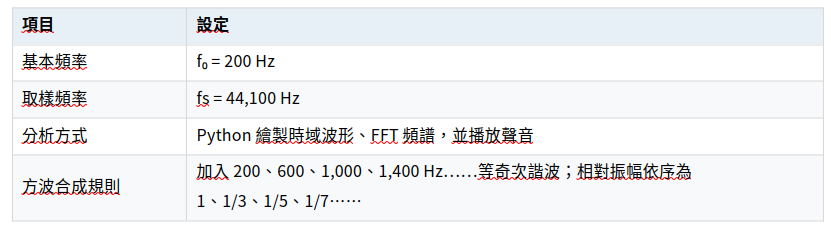

## 實做一 Fourier Series 聲音合成
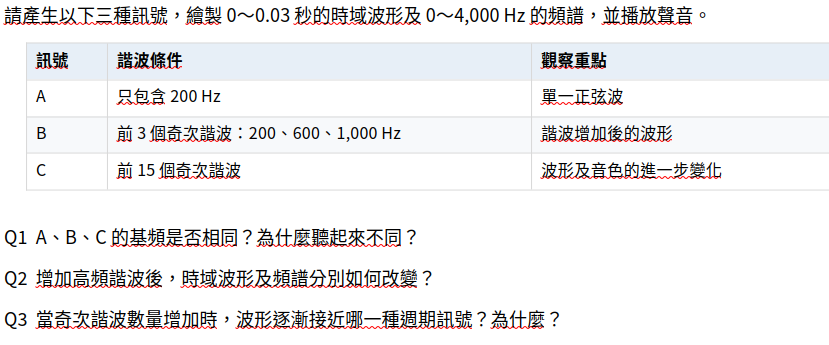

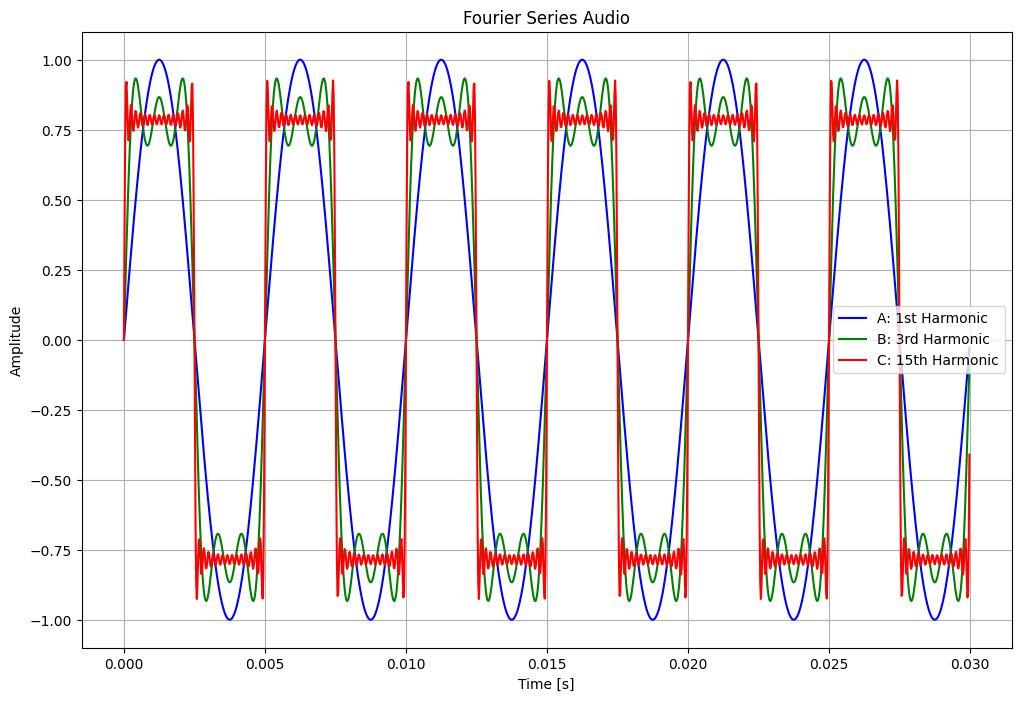

In [32]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Audio

f_0 = 200
fs  = 44.1*1000
duration = 0.03
t = np.linspace(0, duration, int(fs*duration), endpoint=False)

def generate_signal(Number):
    signal = np.zeros_like(t)
    for i in range(1, Number*2, 2):
        signal += (1/i)*np.sin(2 * np.pi * f_0 * i * t)
    return signal
    
A = generate_signal(1)
B = generate_signal(3)
C = generate_signal(15)

plt.figure(figsize=(12, 8))
plt.plot(t, A, label='A: 1st Harmonic', color='blue')
plt.plot(t, B, label='B: 3rd Harmonic', color='green')
plt.plot(t, C, label='C: 15th Harmonic', color='red')
plt.xlabel('Time [s]')
plt.ylabel('Amplitude')
plt.title('Fourier Series Audio')
plt.legend()
plt.grid(True)
plt.show()


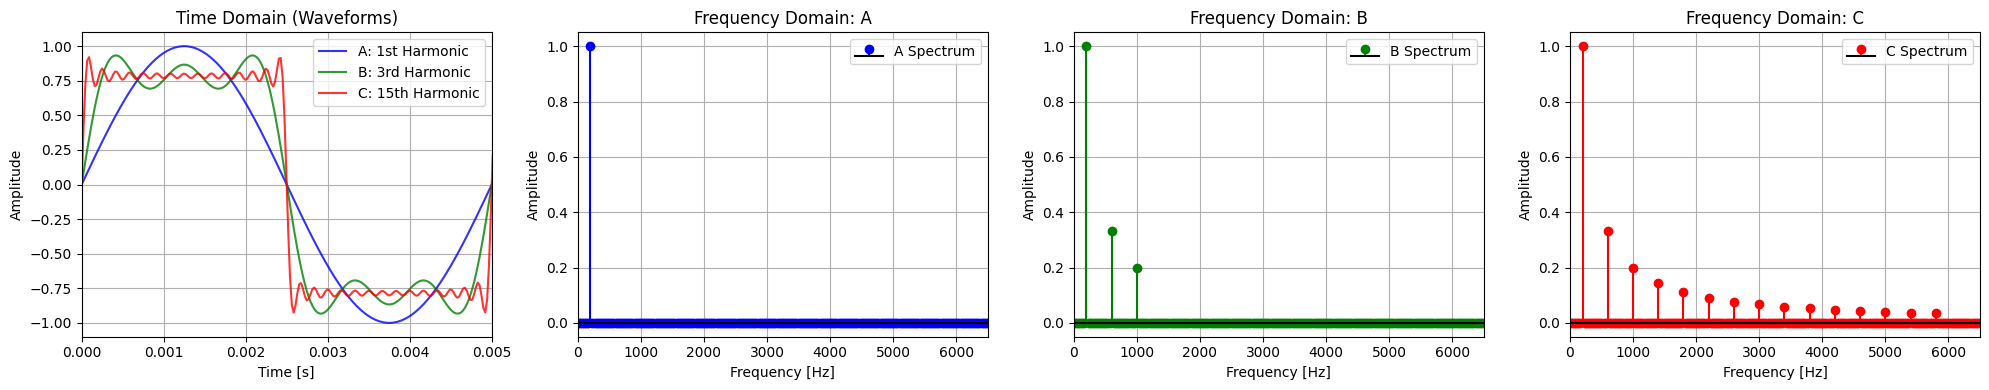

In [33]:
def get_spectrum(signal, fs):
    N = len(signal)
    spectrum = np.fft.fft(signal)
    freq = np.fft.fftfreq(N, 1/fs)
    positive_freq = freq[:N//2]
    positive_amp = (np.abs(spectrum)[:N//2]) / (N/2)
    return positive_freq, positive_amp

freq_A, spectrum_A = get_spectrum(A, fs)
freq_B, spectrum_B = get_spectrum(B, fs)
freq_C, spectrum_C = get_spectrum(C, fs)

fig, (ax1, ax2, ax3, ax4) = plt.subplots(1, 4, figsize=(20, 4))

ax1.plot(t, A, label='A: 1st Harmonic', color='blue', alpha=0.8)
ax1.plot(t, B, label='B: 3rd Harmonic', color='green', alpha=0.8)
ax1.plot(t, C, label='C: 15th Harmonic', color='red', alpha=0.8)
ax1.set_xlabel('Time [s]')
ax1.set_ylabel('Amplitude')
ax1.set_title('Time Domain (Waveforms)')
ax1.set_xlim(0, 0.005) 
ax1.legend(loc='upper right')
ax1.grid(True)

ax2.stem(freq_A, spectrum_A, linefmt='b-', markerfmt='bo', basefmt='k-', label='A Spectrum')
ax2.set_xlim(0, 6500)
ax2.set_xlabel('Frequency [Hz]')
ax2.set_ylabel('Amplitude')
ax2.set_title('Frequency Domain: A')
ax2.legend()
ax2.grid(True)

ax3.stem(freq_B, spectrum_B, linefmt='g-', markerfmt='go', basefmt='k-', label='B Spectrum')
ax3.set_xlim(0, 6500)
ax3.set_xlabel('Frequency [Hz]')
ax3.set_ylabel('Amplitude')
ax3.set_title('Frequency Domain: B')
ax3.legend()
ax3.grid(True)

ax4.stem(freq_C, spectrum_C, linefmt='r-', markerfmt='ro', basefmt='k-', label='C Spectrum')
ax4.set_xlim(0, 6500)
ax4.set_xlabel('Frequency [Hz]')
ax4.set_ylabel('Amplitude')
ax4.set_title('Frequency Domain: C')
ax4.legend()
ax4.grid(True)

plt.tight_layout()
plt.show()

以上是局部放大到只看一個週期

In [34]:
def normalize(sig):
    peak = np.max(np.abs(sig))
    return sig / peak * 0.9 if peak > 0 else sig

duration = 1
t = np.linspace(0, duration, int(fs*duration), endpoint=False)

A = generate_signal(1)
B = generate_signal(3)
C = generate_signal(15)

print("A (1st harmonic):")
display(Audio(normalize(A), rate=fs))

print("B (3rd harmonic):")
display(Audio(normalize(B), rate=fs))

print("C (15th harmonic):")
display(Audio(normalize(C), rate=fs))

A (1st harmonic):


B (3rd harmonic):


C (15th harmonic):


- Q1  A、B、C 的基頻是否相同？為什麼聽起來不同？
    - 基頻皆相同，都是 200 Hz, 基頻決定了聲音的音高，所以這三個聲音的音高是一樣的
    - 因為音色不同, A 只有 200 Hz 的純音, B 和 C 疊加了更高頻率的泛音, 進而產生不同音色
- Q2  增加高頻諧波後，時域波形及頻譜分別如何改變？
    - 原本完整的正弦波, 變得很多曲折, 也更容易出現吉布斯現象
    - 原本 A 在頻譜上只有一根 200 Hz 的譜線, B 和 C 則出現了更高頻率的譜線。
- Q3  當奇次諧波數量增加時，波形逐漸接近哪一種週期訊號？為什麼？
    - 方波
    - 傅立葉級數中，一個理想的方波, 正好可以拆解為基頻加上無限多個奇次諧波, 且振幅按照 1, 1/3, 1/5 ... 遞減, 在項數趨近無限大時，就會接近完美的方波 

## 實作二  使用低通 Filter 改變聲音
將訊號 C 分別通過截止頻率 400、1,000、3,000 Hz 的 Low-pass Filter，觀察並播放濾波前後的訊號。

In [35]:
from scipy.signal import butter, filtfilt

def lowpass_filter(signal, cutoff_freq, fs, order=4):
    nyquist = 0.5 * fs
    normal_cutoff = cutoff_freq / nyquist
    b, a = butter(order, normal_cutoff, btype='low', analog=False)
    filtered_signal = filtfilt(b, a, signal)
    return filtered_signal

C_400 = lowpass_filter(C, 400, fs)
C_1000 = lowpass_filter(C, 1000, fs)
C_3000 = lowpass_filter(C, 3000, fs)

freq_C, spectrum_C = get_spectrum(C, fs)
freq_C_400, spectrum_C_400 = get_spectrum(C_400, fs)
freq_C_1000, spectrum_C_1000 = get_spectrum(C_1000, fs)
freq_C_3000, spectrum_C_3000 = get_spectrum(C_3000, fs)

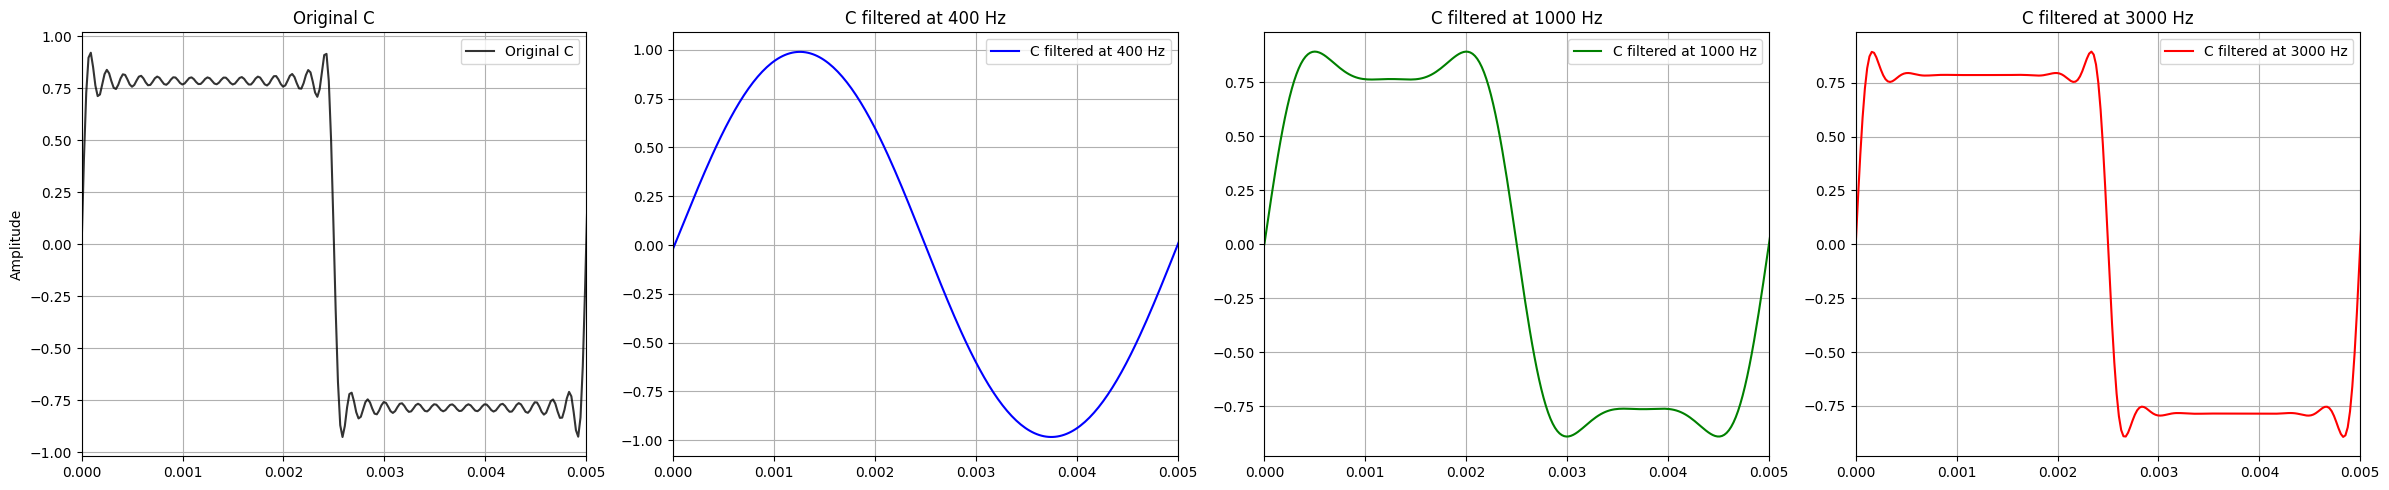

In [36]:
fig, (ax1, ax2, ax3, ax4) = plt.subplots(1, 4, figsize=(24, 5))

ax1.plot(t, C, label='Original C', color='black', alpha=0.8)
ax1.set_xlim(0, 0.005)
ax1.set_ylabel('Amplitude')
ax1.set_title('Original C')
ax1.legend()
ax1.grid(True)

ax2.plot(t, C_400, label='C filtered at 400 Hz', color='blue')
ax2.set_xlim(0, 0.005)
ax2.set_title('C filtered at 400 Hz')
ax2.legend()
ax2.grid(True)

ax3.plot(t, C_1000, label='C filtered at 1000 Hz', color='green')
ax3.set_xlim(0, 0.005)
ax3.set_title('C filtered at 1000 Hz')
ax3.legend()
ax3.grid(True)

ax4.plot(t, C_3000, label='C filtered at 3000 Hz', color='red')
ax4.set_xlim(0, 0.005)
ax4.set_title('C filtered at 3000 Hz')
ax4.legend()
ax4.grid(True)

plt.tight_layout()
plt.show()

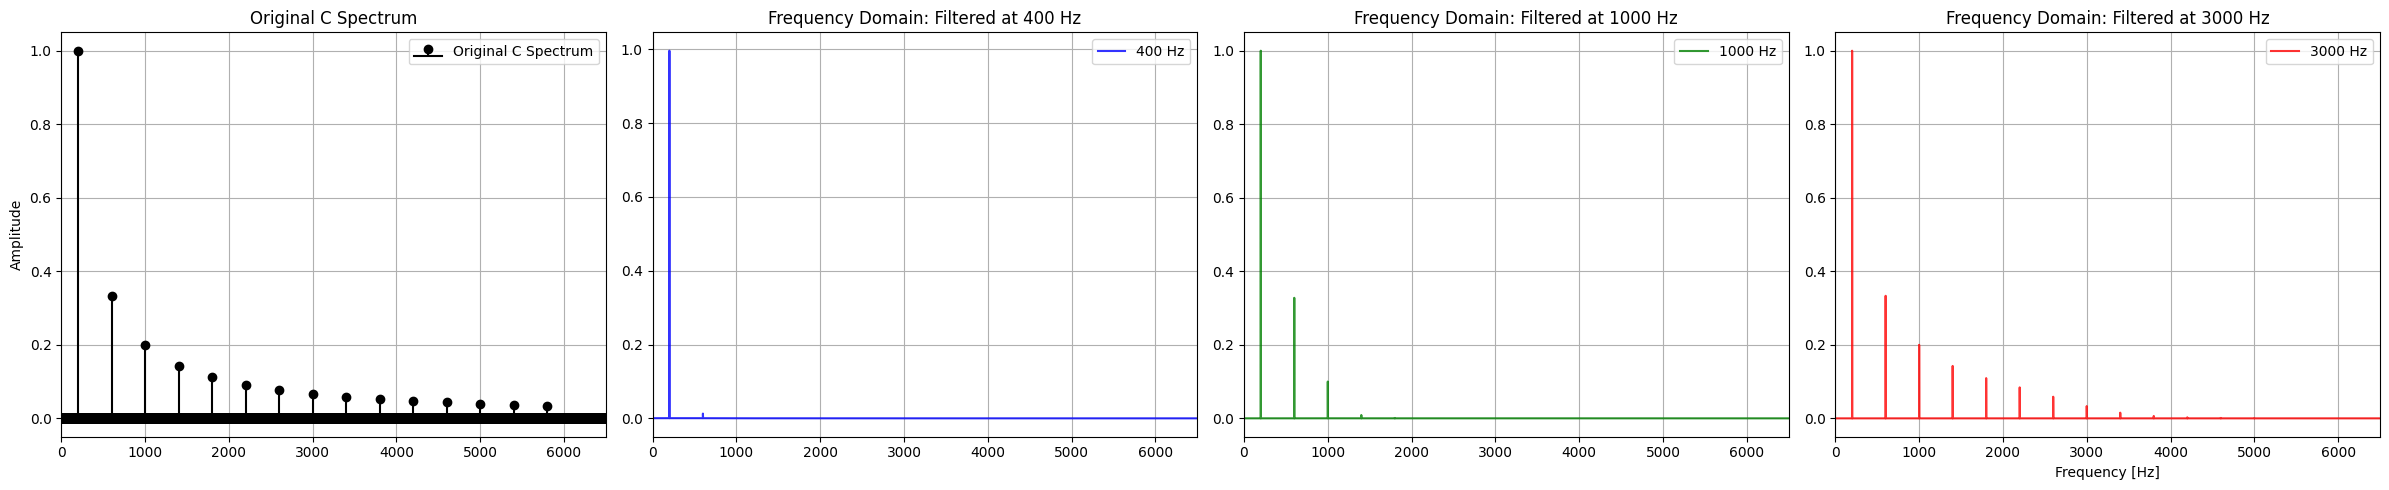

In [37]:
fig2, (ax5, ax6, ax7, ax8) = plt.subplots(1, 4, figsize=(24, 5))

ax5.stem(freq_C, spectrum_C, linefmt='k-', markerfmt='ko', basefmt='k-', label='Original C Spectrum')
ax5.set_xlim(0, 6500)
ax5.set_ylabel('Amplitude')
ax5.set_title('Original C Spectrum')
ax5.legend()
ax5.grid(True)

ax6.plot(freq_C_400, spectrum_C_400, color='blue', label='400 Hz', alpha=0.8)
ax6.set_xlim(0, 6500)
ax6.set_title('Frequency Domain: Filtered at 400 Hz')
ax6.legend()
ax6.grid(True)

ax7.plot(freq_C_1000, spectrum_C_1000, color='green', label='1000 Hz', alpha=0.8)
ax7.set_xlim(0, 6500)
ax7.set_title('Frequency Domain: Filtered at 1000 Hz')
ax7.legend()
ax7.grid(True)

ax8.plot(freq_C_3000, spectrum_C_3000, color='red', label='3000 Hz', alpha=0.8)
ax8.set_xlim(0, 6500)
ax8.set_xlabel('Frequency [Hz]')
ax8.set_title('Frequency Domain: Filtered at 3000 Hz')
ax8.legend()
ax8.grid(True)

plt.tight_layout()
plt.show()

In [38]:
print("Original C:")
display(Audio(normalize(C), rate=fs))

print("LPF 3000 Hz:")
display(Audio(normalize(C_3000), rate=fs))

print("LPF 1000 Hz:")
display(Audio(normalize(C_1000), rate=fs))

print("LPF 400 Hz:")
display(Audio(normalize(C_400), rate=fs))

Original C:


LPF 3000 Hz:


LPF 1000 Hz:


LPF 400 Hz:


- Q4  截止頻率降低時，頻譜中的哪些成分受到較多抑制？
    - 高頻諧波成分, 受到較多的抑制
    - 低通濾波器, 特性就是低頻通過，高頻衰減
- Q5  為什麼經過低通濾波後，波形會逐漸變得平滑？
    - 低通濾波器把這些高頻成分濾除後, 剩下的低頻正弦波, 無法產生銳利的邊緣, 看起來平滑
- Q6  截止頻率會如何影響聲音的音高與音色？請以實際聽到的聲音說明。
    - 音高不受影響
    - 音色有大量高頻, 但是經過低通濾波後，隨著高頻消失，聲音明顯變得更悶

## 實作三  設計自己的電子提示音
假設你負責設計遊戲中的提示音，請自行產生兩種不同音色的週期訊號。至少調整基本頻率、諧波數量、諧波振幅或截止頻率中的兩項。
提供兩種聲音的播放結果、時域波形、頻譜，以及約 100 字的設計說明。

In [43]:
def create_game_audio(k, f_0):
    sig = np.zeros_like(t)
    for i in range(1, k):
        sig += (1/(i*0.25)) * np.sin(2 * np.pi * f_0 * i * t)
    return sig

A = create_game_audio(10, 500)
B = create_game_audio(20, 1000)

print("Game Audio A:")
display(Audio(normalize(A), rate=fs))

print("Game Audio B:")
display(Audio(normalize(B), rate=fs))

Game Audio A:


Game Audio B:


本次設計了兩款遊戲提示音，主要調整基本頻率（$f_0$）與諧波數量（$k$）來區分聽覺回饋：提示音 A（一般確認音）設定較低的基本頻率 $500\text{ Hz}$，並疊加第 $1$ 至 $9$ 階諧波，在時域上呈現較寬的週期與溫和的波動起伏，聽感沉穩飽滿；提示音 B（得分音）則將基本頻率提高一倍至 $1000\text{ Hz}$，並將諧波數量擴增至第 $19$ 階，使其時域波形更為密集且尖峰銳利、高頻泛音豐富，聽感更為高亢清脆。

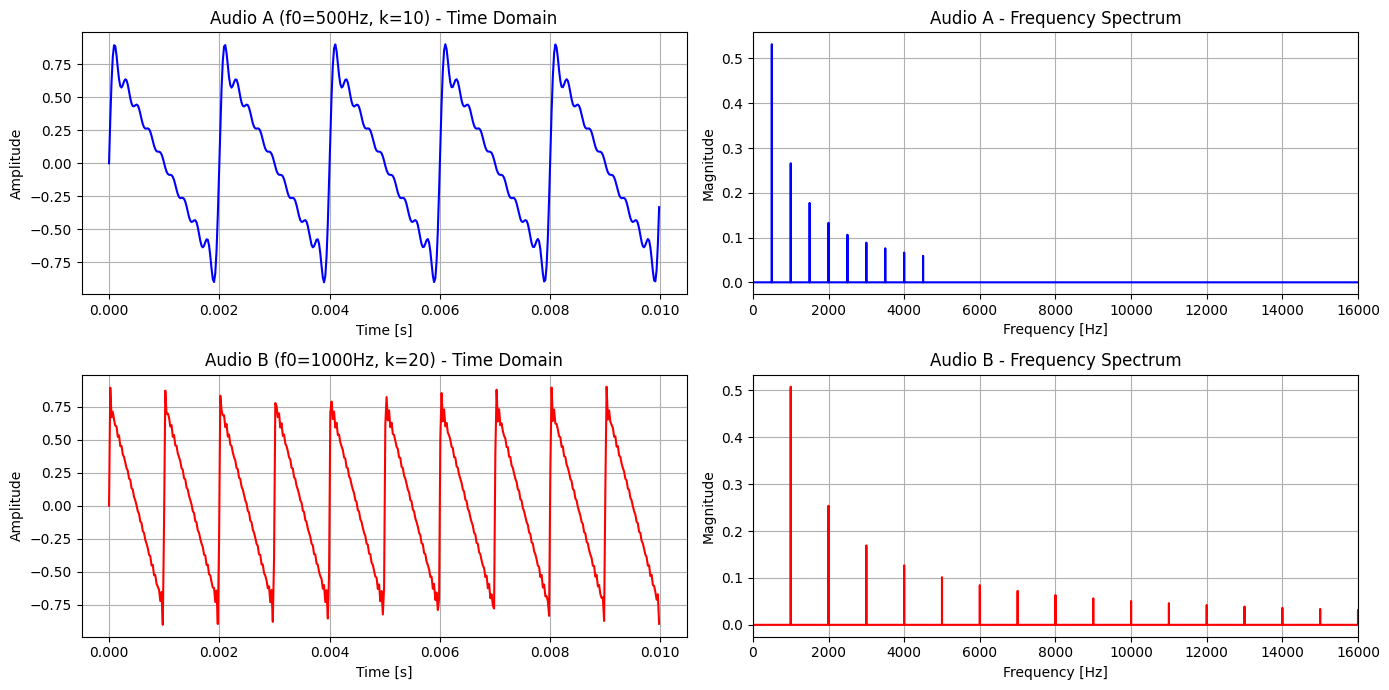

In [44]:
t_zoom = t[:int(0.01 * fs)]
freq_A, spec_A = get_spectrum(normalize(A), fs)
freq_B, spec_B = get_spectrum(normalize(B), fs)

fig, axs = plt.subplots(2, 2, figsize=(14, 7))

axs[0, 0].plot(t_zoom, normalize(A)[:len(t_zoom)], color='blue')
axs[0, 0].set_title('Audio A (f0=500Hz, k=10) - Time Domain')
axs[0, 0].set_xlabel('Time [s]')
axs[0, 0].set_ylabel('Amplitude')
axs[0, 0].grid(True)

axs[0, 1].plot(freq_A, spec_A, color='blue')
axs[0, 1].set_xlim(0, 16000)
axs[0, 1].set_title('Audio A - Frequency Spectrum')
axs[0, 1].set_xlabel('Frequency [Hz]')
axs[0, 1].set_ylabel('Magnitude')
axs[0, 1].grid(True)

axs[1, 0].plot(t_zoom, normalize(B)[:len(t_zoom)], color='red')
axs[1, 0].set_title('Audio B (f0=1000Hz, k=20) - Time Domain')
axs[1, 0].set_xlabel('Time [s]')
axs[1, 0].set_ylabel('Amplitude')
axs[1, 0].grid(True)

axs[1, 1].plot(freq_B, spec_B, color='red')
axs[1, 1].set_xlim(0, 16000)
axs[1, 1].set_title('Audio B - Frequency Spectrum')
axs[1, 1].set_xlabel('Frequency [Hz]')
axs[1, 1].set_ylabel('Magnitude')
axs[1, 1].grid(True)

plt.tight_layout()
plt.show()

- Q7  請比較聲音低通濾波與先前影像 Convolution 的模糊處理：兩者有哪些相似之處？
    - 皆運用到卷積的特性，聲音低通濾波是 1D 時間訊號與濾波器做 1D 卷積，影像模糊則是 2D 像素矩陣與平滑卷積核做 2D 卷積
    - 且影像模糊本身即是，保留低頻消除高頻與低通濾波意義相同